# NYC service requests — EDA, probability and statistical analysis
Preserve the original complaint, location, city, grouped descriptor, response-time, long-duration and t-test analyses. Add explicit quality checks, temporal context, probability/uncertainty and corrected statistical comparisons. There is no classifier, regressor, clustering or forecasting model.

A row is one request identified by Unique Key. This export must not be treated as a random sample of residents or all NYC complaints. Request creation-to-closure time is an administrative duration, not a direct measure of satisfaction or the exact time an issue was resolved.


## 1. Load the local source and inspect scope


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as sts
from IPython.display import display
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 20)
SEED = 42
ALPHA = 0.05  # Significance level; 95% confidence = 1 - alpha.

from itertools import combinations
DATA_PATH = next((candidate for location in (Path.cwd(), *Path.cwd().parents)
                  for candidate in (location / "nyc_311_data.csv", location / "statistics/service_requests_analysis/nyc_311_data.csv")
                  if candidate.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Start Jupyter from the repository or service_requests_analysis folder.")
raw_data = pd.read_csv(DATA_PATH, low_memory=False)
required = ["Unique Key", "Created Date", "Closed Date", "Complaint Type", "Location Type", "City", "Borough", "Status", "Descriptor", "Agency"]
if set(required) - set(raw_data):
    raise ValueError("Service-request source is missing required columns")
display(raw_data[required].head())
schema = pd.DataFrame({"dtype": raw_data.dtypes.astype(str), "missing_count": raw_data.isna().sum(),
                      "missing_percent": raw_data.isna().mean() * 100, "unique": raw_data.nunique()})
display(schema.sort_values("missing_percent", ascending=False))
print("Source shape:", raw_data.shape)
display(raw_data.Agency.value_counts(dropna=False).to_frame("requests"))
display(raw_data.Status.value_counts(dropna=False).to_frame("requests"))


,Unique Key,Created Date,Closed Date,Complaint Type,Location Type,City,Borough,Status,Descriptor,Agency
0,32310363,12/31/2015 11:59:45 PM,01-01-16 0:55,Noise - Street/Sidewalk,Street/Sidewalk,NEW YORK,MANHATTAN,Closed,Loud Music/Party,NYPD
1,32309934,12/31/2015 11:59:44 PM,01-01-16 1:26,Blocked Driveway,Street/Sidewalk,ASTORIA,QUEENS,Closed,No Access,NYPD
2,32309159,12/31/2015 11:59:29 PM,01-01-16 4:51,Blocked Driveway,Street/Sidewalk,BRONX,BRONX,Closed,No Access,NYPD
3,32305098,12/31/2015 11:57:46 PM,01-01-16 7:43,Illegal Parking,Street/Sidewalk,BRONX,BRONX,Closed,Commercial Overnight Parking,NYPD
4,32306529,12/31/2015 11:56:58 PM,01-01-16 3:24,Illegal Parking,Street/Sidewalk,ELMHURST,QUEENS,Closed,Blocked Sidewalk,NYPD


,dtype,missing_count,missing_percent,unique
School or Citywide Complaint,float64,300698,100.0,0
Vehicle Type,float64,300698,100.0,0
Taxi Company Borough,float64,300698,100.0,0
Taxi Pick Up Location,float64,300698,100.0,0
Garage Lot Name,float64,300698,100.0,0
...,...,...,...,...
School Name,str,0,0.0,2
Park Borough,str,0,0.0,6
Park Facility Name,str,0,0.0,2
Created Date,str,0,0.0,259493


Source shape: (300698, 53)


,requests
Agency,
NYPD,300698


,requests
Status,
Closed,298471
Open,1439
Assigned,786
Draft,2


## 2. Missing columns, identity and datetime cleanup
Preserve the raw frame, dynamically identify columns more than 99% missing, and remove those columns only from the working analysis frame. Keep all requests for volume/probability analyses, including requests that are not closed. Exact repeated records can be removed, but conflicting repeated keys require review.

This CSV mixes month/day/year 12-hour timestamps with month-day-two-digit-year 24-hour timestamps. Parse each explicit format and audit remaining failures. These are timezone-naive local timestamps; DST effects cannot be resolved without additional metadata.


In [2]:
sparse_columns = schema.index[schema.missing_percent > 99].tolist()
protected = set(required)
requests = raw_data.drop(columns=[column for column in sparse_columns if column not in protected]).drop_duplicates().copy()
duplicate_records_removed = len(raw_data) - len(requests)
if requests["Unique Key"].isna().any() or requests["Unique Key"].duplicated().any():
    raise ValueError("Missing or conflicting request keys; inspect identity records before analysis")
for column in ["Complaint Type", "Location Type", "City", "Borough", "Status", "Descriptor", "Agency"]:
    requests[column] = requests[column].astype("string").str.strip().replace("", pd.NA)
requests["City"] = requests.City.str.upper()
requests["Borough"] = requests.Borough.str.upper()

def parse_311_dates(values):
    slash = pd.to_datetime(values, format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    dash = pd.to_datetime(values.where(slash.isna()), format="%m-%d-%y %H:%M", errors="coerce")
    return slash.fillna(dash)

date_audit_records = []
for column in ["Created Date", "Closed Date"]:
    original = requests[column].copy()
    parsed = parse_311_dates(original)
    date_audit_records.append({"column": column, "missing_source": int(original.isna().sum()),
                               "unparsed_nonmissing": int((original.notna() & parsed.isna()).sum()),
                               "earliest": parsed.min(), "latest": parsed.max()})
    requests[column] = parsed
date_audit = pd.DataFrame(date_audit_records)
display(date_audit)
print("More-than-99%-missing columns omitted:", sparse_columns)
requests["request_date"] = requests["Created Date"].dt.normalize()
requests["request_hour"] = requests["Created Date"].dt.hour
requests["request_weekday"] = requests["Created Date"].dt.day_name()
requests["Request_Closing_Time(Mins)"] = (requests["Closed Date"] - requests["Created Date"]).dt.total_seconds() / 60
duration = requests["Request_Closing_Time(Mins)"]
valid_duration = requests.Status.eq("Closed") & duration.notna() & duration.ge(0)
clean_data = requests.loc[valid_duration].copy()
clean_data["closing_hours"] = clean_data["Request_Closing_Time(Mins)"] / 60
service_quality = {
    "source_rows": len(raw_data), "retained_requests": len(requests), "duplicates_removed": duplicate_records_removed,
    "sparse_columns_omitted": len([column for column in sparse_columns if column not in protected]),
    "status_not_closed": int(requests.Status.ne("Closed").sum()), "valid_closed_duration_rows": len(clean_data),
    "missing_duration_rows": int(duration.isna().sum()), "negative_duration_rows": int(duration.lt(0).sum()),
    "duration_rows_over_24_hours": int(clean_data.closing_hours.ge(24).sum()),
    "dated_but_not_closed_rows": int((requests.Status.ne("Closed") & duration.notna()).sum()),
    "unparsed_nonmissing_dates": int(date_audit.unparsed_nonmissing.sum()),
    "created_start": str(requests["Created Date"].min()), "created_end": str(requests["Created Date"].max()),
}
display(pd.Series(service_quality).to_frame("value"))
assert requests["Unique Key"].is_unique
assert clean_data["Request_Closing_Time(Mins)"].ge(0).all()


,column,missing_source,unparsed_nonmissing,earliest,latest
0,Created Date,0,0,2015-03-29 00:33:01,2015-12-31 23:59:45
1,Closed Date,2164,0,2015-03-29 00:57:23,2016-01-03 16:22:00


More-than-99%-missing columns omitted: ['Landmark', 'School or Citywide Complaint', 'Vehicle Type', 'Taxi Company Borough', 'Taxi Pick Up Location', 'Bridge Highway Name', 'Bridge Highway Direction', 'Road Ramp', 'Bridge Highway Segment', 'Garage Lot Name', 'Ferry Direction', 'Ferry Terminal Name']


,value
source_rows,300698
retained_requests,300698
duplicates_removed,0
sparse_columns_omitted,12
status_not_closed,2227
valid_closed_duration_rows,298471
missing_duration_rows,2164
negative_duration_rows,0
duration_rows_over_24_hours,3682
dated_but_not_closed_rows,63


### Observations: scope and cleaning
The export contains **300,698 unique requests**, all recorded under NYPD, created from **29 March through 31 December 2015**. Twelve columns exceed 99% missingness and are omitted only from the analysis frame. Both timestamp formats parse with **zero nonmissing failures**; the CSV is unchanged.

Volume analyses retain all requests. Closure analysis uses **298,471 Closed requests** with valid nonnegative dates. **2,227 requests are not Closed**, and 63 of those nevertheless have a closing timestamp; they remain outside the explicitly defined closed cohort. Unique keys identify records but do not establish independence between incidents.


## 3. Closing-time distribution and selection
Use total_seconds(), not timedelta.seconds: the latter drops complete days. Duration summaries use only Closed requests with valid nonnegative dates. Open/assigned requests remain in volume analysis and are not given a zero duration. The closed-only distribution is conditional and may underrepresent slow unresolved requests.


,minutes
count,298471.000000
mean,258.842316
std,365.367854
min,1.000000
50%,162.883333
75%,321.000000
90%,549.000000
95%,777.766667
99%,1571.416667
max,35572.366667


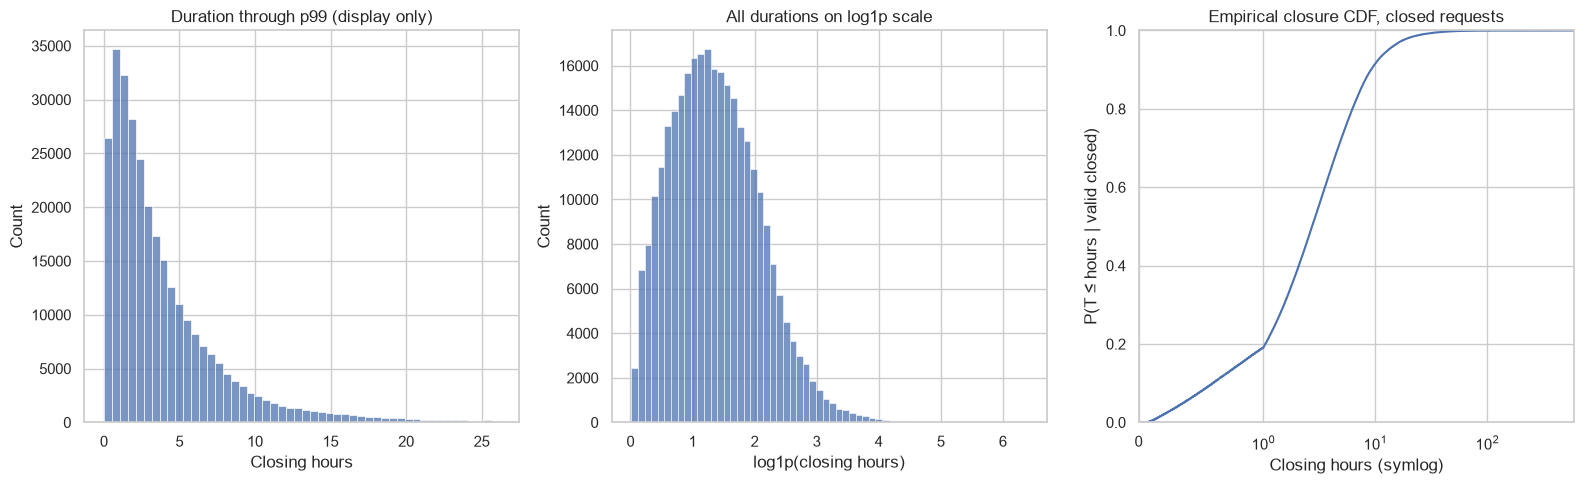

In [3]:
duration_summary = clean_data["Request_Closing_Time(Mins)"].describe(percentiles=[.5, .75, .90, .95, .99])
display(duration_summary.to_frame("minutes"))
duration_metrics = {"mean_minutes": float(duration_summary["mean"]), "median_minutes": float(duration_summary["50%"]),
                    "p75_minutes": float(duration_summary["75%"]), "p90_minutes": float(duration_summary["90%"]),
                    "p95_minutes": float(duration_summary["95%"]), "p99_minutes": float(duration_summary["99%"]),
                    "max_minutes": float(duration_summary["max"]), "within_6h_fraction": float(clean_data.closing_hours.le(6).mean())}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.histplot(clean_data.loc[clean_data.closing_hours <= clean_data.closing_hours.quantile(.99), "closing_hours"], bins=50, ax=axes[0])
axes[0].set(title="Duration through p99 (display only)", xlabel="Closing hours")
sns.histplot(np.log1p(clean_data.closing_hours), bins=60, ax=axes[1])
axes[1].set(title="All durations on log1p scale", xlabel="log1p(closing hours)")
sns.ecdfplot(data=clean_data, x="closing_hours", ax=axes[2])
axes[2].set_xscale("symlog", linthresh=1)
axes[2].set_xlim(0, clean_data.closing_hours.max())
axes[2].set_ylim(0, 1)
axes[2].set(title="Empirical closure CDF, closed requests", xlabel="Closing hours (symlog)", ylabel="P(T ≤ hours | valid closed)")
plt.tight_layout()
plt.show()


### Observations: corrected closing durations
Mean closure time is **258.84 minutes (4.31 hours)**, versus a median of **162.88 minutes**. The 75th percentile is **321 minutes**, p90 **549**, and p99 **1571**. The mean exceeds the median because of the long right tail.

**3,682 closed requests take at least 24 hours**; the maximum recorded interval is about **24.7 days**. On the same cohort, the old day-wrapping calculation would give **235.74 minutes**, understating the mean by **23.10 minutes**. The p99-limited histogram is a display choice only; all valid durations remain in summaries and tests. These statistics concern closed requests, not future or unresolved requests.


## 4. Complaint frequency and empirical shares
Retain the original top-complaint view, using all requests as the stated denominator. The six familiar noise/vehicle categories are counted explicitly rather than assuming their share is 90%. Display counts and percentages together.


,complaint_type,requests,percent_all_requests
0,Blocked Driveway,77044,25.62172
1,Illegal Parking,75361,25.062022
2,Noise - Street/Sidewalk,48612,16.166386
3,Noise - Commercial,35577,11.831472
4,Derelict Vehicle,17718,5.892291
...,...,...,...
19,Graffiti,113,0.037579
20,Agency Issues,6,0.001995
21,Squeegee,4,0.00133
22,Ferry Complaint,2,0.000665


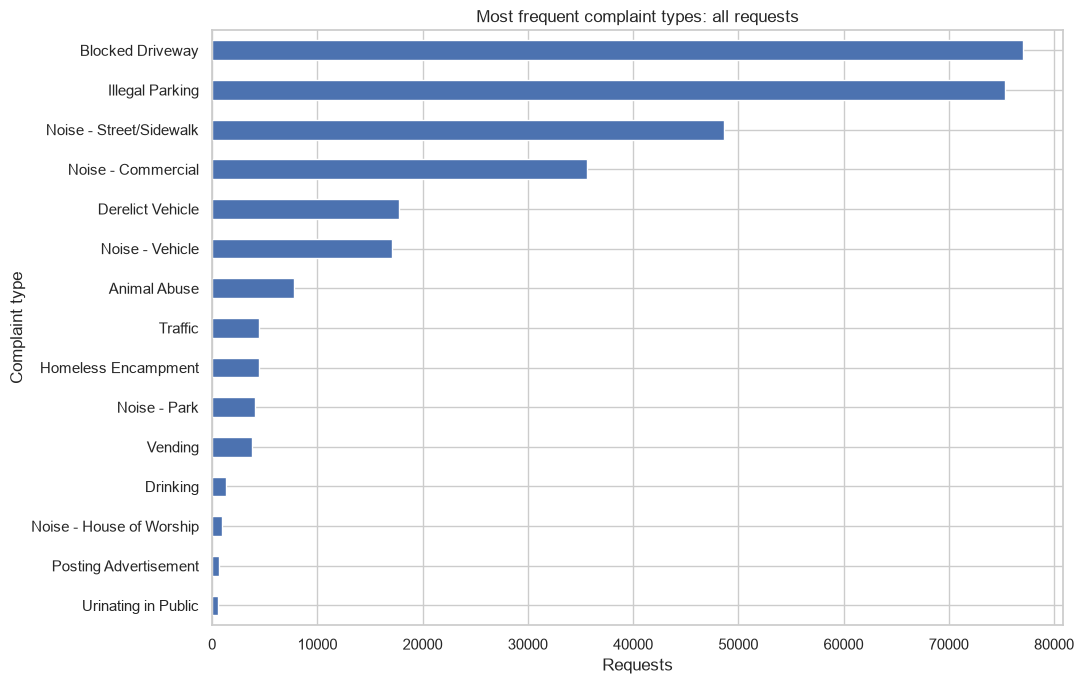

Share of the original six complaint types: 0.9025500668444751


In [4]:
complaint_counts = requests["Complaint Type"].fillna("Unknown").value_counts()
complaint_table = complaint_counts.rename_axis("complaint_type").reset_index(name="requests")
complaint_table["percent_all_requests"] = complaint_table.requests / len(requests) * 100
display(complaint_table)
ORIGINAL_SIX = ["Blocked Driveway", "Illegal Parking", "Noise - Street/Sidewalk", "Noise - Commercial", "Derelict Vehicle", "Noise - Vehicle"]
six_share = float(complaint_counts.reindex(ORIGINAL_SIX, fill_value=0).sum() / len(requests))
fig, ax = plt.subplots(figsize=(11, 7))
complaint_counts.head(15).sort_values().plot.barh(ax=ax)
ax.set(title="Most frequent complaint types: all requests", xlabel="Requests", ylabel="Complaint type")
plt.tight_layout()
plt.show()
print("Share of the original six complaint types:", six_share)


### Observations: complaint mix
Blocked Driveway contributes **77,044 requests (25.62%)**, followed closely by Illegal Parking with **75,361 (25.06%)**. The six original vehicle/noise categories total **90.26% of all requests**, substantiating the original approximately-90% description for this export.

These are recorded-request frequencies, not rates per resident or measures of the underlying prevalence of problems. Reporting access and repeat incidents can affect counts.


## 5. Location, city and borough distributions
Retain location/city frequency views, but avoid a pie restricted to a top subset with an unstated denominator. Location pie categories include Other so they sum to all requests; city and borough views use counts. City labels in this export include neighborhood names and are not distinct municipal jurisdictions. Counts are not population-adjusted complaint rates.


,requests
Location Type,
Street/Sidewalk,249299
Store/Commercial,20381
Club/Bar/Restaurant,17360
Residential Building/House,6960
Park/Playground,4773
House of Worship,929
Residential Building,227
Highway,215
Unknown,131


,requests
City,
BROOKLYN,98307
NEW YORK,65994
BRONX,40702
STATEN ISLAND,12343
JAMAICA,7296
ASTORIA,7047
FLUSHING,5971
RIDGEWOOD,5163
CORONA,4295


,requests
Borough,
BROOKLYN,98307
QUEENS,80641
MANHATTAN,66131
BRONX,40702
STATEN ISLAND,12343
UNSPECIFIED,2574


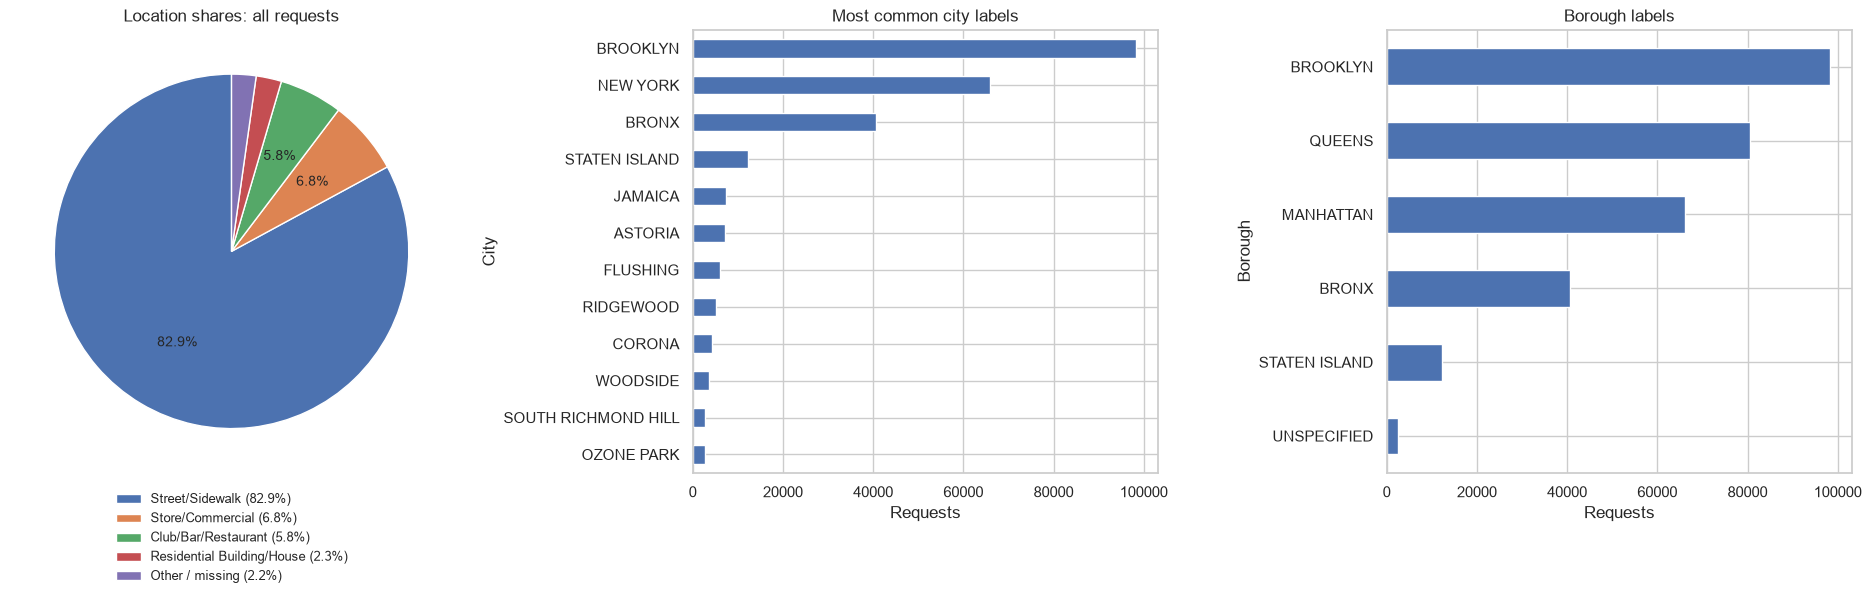

In [5]:
location_counts = requests["Location Type"].fillna("Unknown").value_counts()
city_counts = requests.City.fillna("Unknown").value_counts()
borough_counts = requests.Borough.fillna("Unknown").value_counts()
display(location_counts.head(12).to_frame("requests"))
display(city_counts.head(15).to_frame("requests"))
display(borough_counts.to_frame("requests"))
location_pie = location_counts.head(4).copy()
location_pie.loc["Other / missing"] = location_counts.iloc[4:].sum()
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
wedges, _, _ = axes[0].pie(location_pie, autopct=lambda percent: f"{percent:.1f}%" if percent >= 3 else "",
                          startangle=90, textprops={"fontsize": 10})
legend_labels = [f"{name} ({value / len(requests):.1%})" for name, value in location_pie.items()]
axes[0].legend(wedges, legend_labels, loc="upper center", bbox_to_anchor=(.5, -.02), frameon=False, fontsize=9)
axes[0].set_title("Location shares: all requests")
city_counts.head(12).sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Most common city labels", xlabel="Requests")
borough_counts.sort_values().plot.barh(ax=axes[2])
axes[2].set(title="Borough labels", xlabel="Requests")
plt.tight_layout()
plt.show()
place_summary = {
    "public_location_share": float(location_counts.reindex(["Street/Sidewalk", "Store/Commercial", "Club/Bar/Restaurant"], fill_value=0).sum() / len(requests)),
    "brooklyn_newyork_bronx_city_share": float(city_counts.reindex(["BROOKLYN", "NEW YORK", "BRONX"], fill_value=0).sum() / len(requests)),
    "missing_city_rows": int(requests.City.isna().sum()),
}


### Observations: location and geography
Street/Sidewalk is the dominant location with **249,299 requests**. Street/Sidewalk, Store/Commercial and Club/Bar/Restaurant together account for **95.46% of all requests**.

BROOKLYN, NEW YORK and BRONX city labels together contribute **68.18%**, not the original 80.2% claim. The corrected denominator is all requests rather than a top-city subset used in a pie. City is missing for **2,614 records**. Borough is a separate field; neither raw geography counts nor these city labels establish which area has the highest population-adjusted need.


## 6. Grouped city/location/descriptor counts
Keep the original grouped table with explicit missing-category handling. Showing the busiest combinations avoids printing tens of thousands of groups. Descriptor strings are recorded complaint details, not independent measurements of severity.


In [6]:
grouped_counts = requests.groupby(["City", "Location Type", "Descriptor"], dropna=False)["Unique Key"].size().rename("requests").sort_values(ascending=False)
display(grouped_counts.head(25).to_frame())
print("Grouped requests accounted for:", int(grouped_counts.sum()))


requests
City     Location Type   Descriptor                             
BROOKLYN Street/Sidewalk No Access                         21408
NEW YORK Street/Sidewalk Loud Music/Party                  13674
BRONX    Street/Sidewalk No Access                          9880
BROOKLYN Street/Sidewalk Loud Music/Party                   8587
                         Posted Parking Sign Violation      7690
...                                                          ...
BRONX    Street/Sidewalk Partial Access                     2871
NEW YORK Street/Sidewalk Car/Truck Music                    2862
BRONX    Street/Sidewalk Loud Talking                       2718
                         Posted Parking Sign Violation      2340
NEW YORK Street/Sidewalk <NA>                               2298

[25 rows x 1 columns]

Grouped requests accounted for: 300698


## 7. Creation-time patterns
Add daily, monthly, weekday and hour summaries. The first and last dates may be partial days. Monthly comparisons include the number of covered calendar days; incomplete months must not be compared as if their exposure were equal. These are descriptive counts, not a time-series forecast.


,requests,covered_days,mean_per_covered_day
month,,,
2015-03,2471,3,823.666667
2015-04,27305,30,910.166667
2015-05,36437,31,1175.387097
2015-06,35315,30,1177.166667
2015-07,34888,31,1125.419355
2015-08,34956,31,1127.612903
2015-09,35427,30,1180.900000
2015-10,32605,31,1051.774194
2015-11,30773,30,1025.766667


,count,mean,median
weekday,,,
Monday,40,1012.225000,1000.5
Tuesday,40,988.775000,983.5
Wednesday,40,994.700000,981.0
Thursday,40,1033.550000,1018.0
Friday,39,1128.076923,1152.0
Saturday,39,1219.589744,1245.0
Sunday,40,1199.225000,1214.0


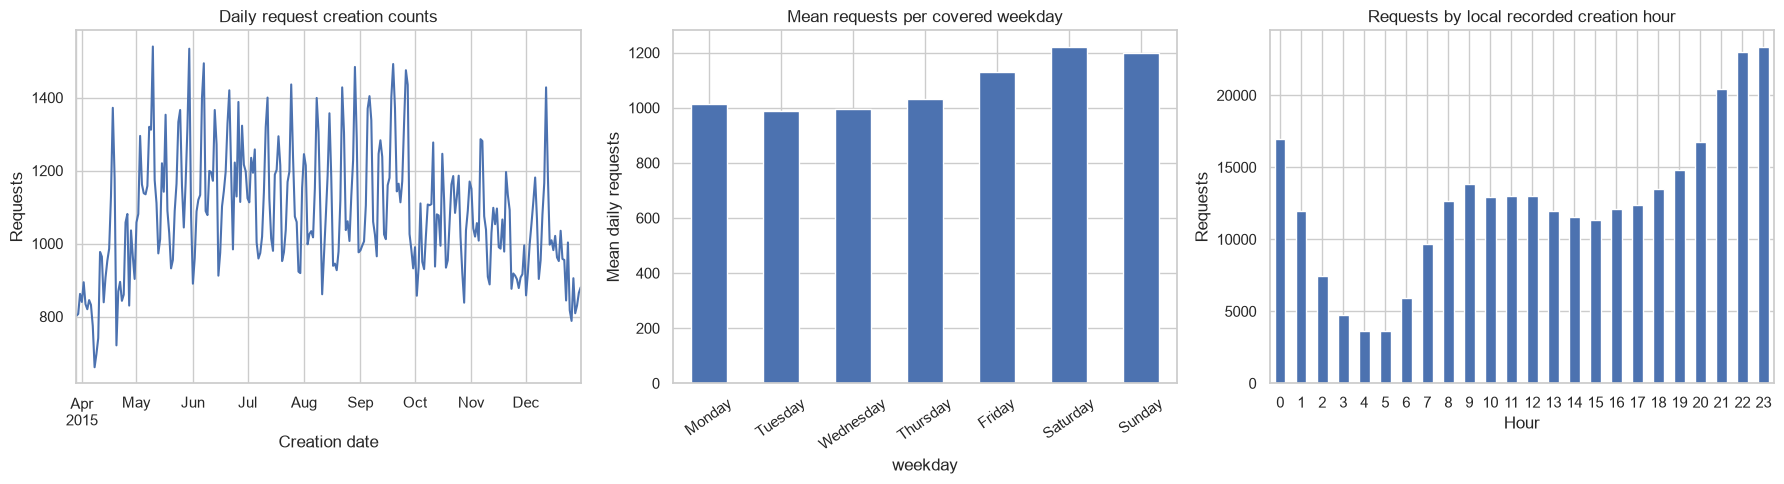

In [7]:
date_range = pd.date_range(requests.request_date.min(), requests.request_date.max(), freq="D")
daily_counts = requests.groupby("request_date").size().reindex(date_range, fill_value=0)
daily_frame = daily_counts.rename("requests").to_frame()
daily_frame["month"] = daily_frame.index.to_period("M").astype(str)
monthly_counts = daily_frame.groupby("month").agg(requests=("requests", "sum"), covered_days=("requests", "size"), mean_per_covered_day=("requests", "mean"))
weekday_daily = daily_frame.assign(weekday=daily_frame.index.day_name()).groupby("weekday").requests.agg(["count", "mean", "median"]).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
hourly_counts = requests.request_hour.value_counts().sort_index()
display(monthly_counts)
display(weekday_daily)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
daily_counts.plot(ax=axes[0])
axes[0].set(title="Daily request creation counts", xlabel="Creation date", ylabel="Requests")
weekday_daily["mean"].plot.bar(ax=axes[1], rot=35)
axes[1].set(title="Mean requests per covered weekday", ylabel="Mean daily requests")
hourly_counts.plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Requests by local recorded creation hour", xlabel="Hour", ylabel="Requests")
plt.tight_layout()
plt.show()
temporal_summary = {"covered_days": len(daily_counts), "peak_hour": int(hourly_counts.idxmax()),
                    "peak_weekday": str(weekday_daily["mean"].idxmax()), "daily_mean": float(daily_counts.mean()),
                    "lag1_daily_count_correlation": float(daily_counts.autocorr(lag=1))}


### Observations: time patterns
The export spans **278 covered calendar days**, averaging **1,082 created requests per day**. March includes only three covered days, so its small monthly total is not evidence of an unusually quiet full month. The largest hourly count is at **23:00**, and **Saturday** has the highest mean daily count among weekdays in this sample.

Lag-one daily-count correlation is **0.64**. This serial structure supports examining temporal dependence rather than treating hundreds of thousands of request rows as automatically independent. The plots describe this historical export and do not predict later activity.


## 8. Mean, median and tail closure times by complaint type
Retain the original average-response-time table, now aligned directly by complaint labels and augmented with sample size, median, p90 and the chance of closing within six hours. Small categories can produce unstable means. Display categories with at least 100 closed requests separately from the full summary.

Use the actual >6-hour threshold for the original long-request view, rather than assuming the last 50,000 sorted rows correspond to that threshold.


,requests,mean_minutes,median_minutes,p90_minutes,within_6h
Complaint Type,,,,,
Animal in a Park,1,20210.083333,20210.083333,20210.083333,0.000000
Derelict Vehicle,17585,441.804699,247.000000,976.253333,0.631618
Graffiti,113,429.075074,272.000000,907.920000,0.619469
Agency Issues,6,315.619444,294.283333,537.500000,0.500000
Animal Abuse,7766,312.817300,198.000000,657.000000,0.726371
...,...,...,...,...,...
Noise - Park,4021,204.539907,132.683333,445.950000,0.839095
Noise - House of Worship,929,191.597901,112.000000,431.800000,0.861141
Noise - Commercial,35245,188.829150,124.466667,398.880000,0.874394


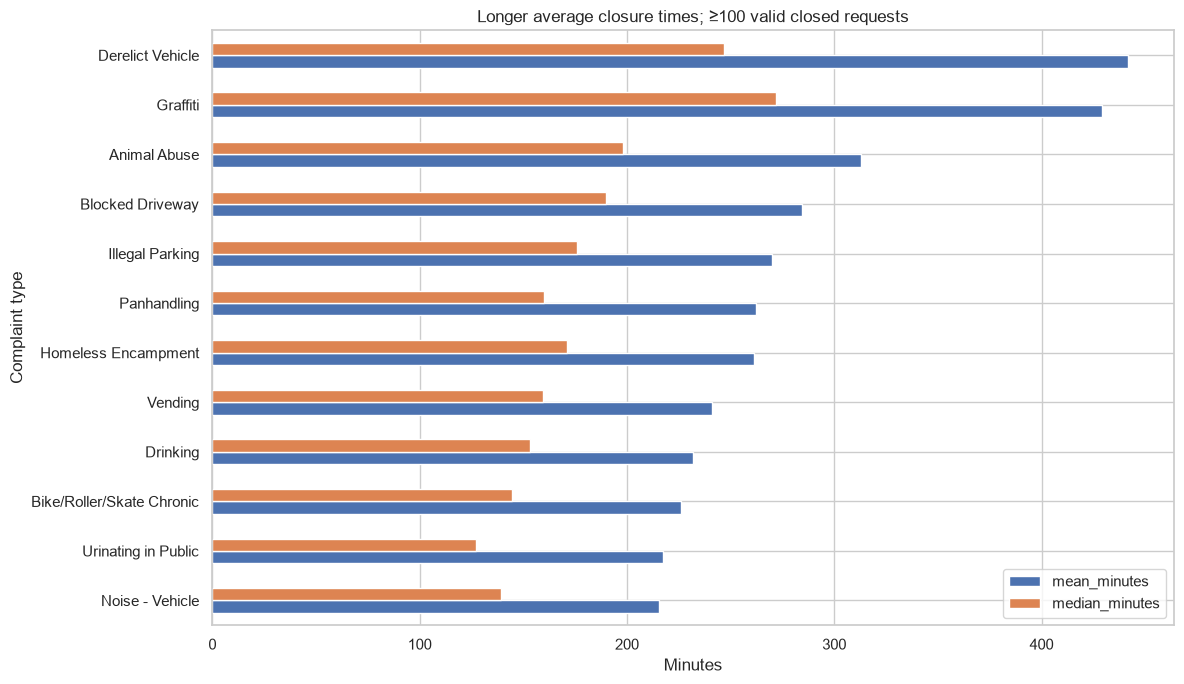

,long_requests,mean_hours,median_hours,all_valid_closed,fraction_over_6h
Complaint Type,,,,,
Blocked Driveway,19015,11.348333,8.950000,76793,0.247614
Illegal Parking,17332,11.371132,8.933333,74515,0.232597
Noise - Street/Sidewalk,7198,10.898762,8.266667,48068,0.149746
Derelict Vehicle,6478,15.707637,11.101528,17585,0.368382
Noise - Commercial,4427,10.433620,8.016667,35245,0.125606
...,...,...,...,...,...
Posting Advertisement,34,9.555400,8.225000,647,0.052550
Illegal Fireworks,22,9.874697,8.241667,168,0.130952
Agency Issues,3,8.257963,7.533333,6,0.500000


Valid closed requests exceeding six hours: 63220


In [8]:
response_by_type = clean_data.groupby("Complaint Type")["Request_Closing_Time(Mins)"].agg(
    requests="size", mean_minutes="mean", median_minutes="median", p90_minutes=lambda values: values.quantile(.9),
    within_6h=lambda values: values.le(360).mean())
response_by_type = response_by_type.sort_values("mean_minutes", ascending=False)
display(response_by_type)
frequent_response = response_by_type.loc[response_by_type.requests >= 100]
fig, ax = plt.subplots(figsize=(12, 7))
frequent_response.head(12)[["mean_minutes", "median_minutes"]].sort_values("mean_minutes").plot.barh(ax=ax)
ax.set(title="Longer average closure times; ≥100 valid closed requests", xlabel="Minutes", ylabel="Complaint type")
plt.tight_layout()
plt.show()
long_requests = clean_data.loc[clean_data.closing_hours > 6]
long_summary = long_requests.groupby("Complaint Type").closing_hours.agg(long_requests="size", mean_hours="mean", median_hours="median").sort_values("long_requests", ascending=False)
long_summary = long_summary.join(response_by_type.requests.rename("all_valid_closed"))
long_summary["fraction_over_6h"] = long_summary.long_requests / long_summary.all_valid_closed
display(long_summary)
print("Valid closed requests exceeding six hours:", len(long_requests))


### Observations: complaint-specific times and long requests
Among categories with at least 100 valid closed requests, Derelict Vehicle has the longest mean: **441.8 minutes (7.36 hours)** across **17,585 requests**, with median **247 minutes**. Graffiti averages **429.1 minutes**, but has only **113 observations**. The single Animal in a Park record and six Agency Issues records cannot support stable category rankings.

Exactly **63,220 requests (21.18%)** exceed six hours. Blocked Driveway and Illegal Parking contribute **19,015** and **17,332** of these long cases because of their high volume. Derelict Vehicle has a larger within-category tail fraction (**36.84%**) than either. Counts of long cases and probabilities of a long case are different quantities. These elapsed-time differences alone do not establish why complaints take longer.


## 9. Probability, conditioning and uncertainty
Probability questions specify their denominator: complaint/borough events use all requests, while closure-within-six-hours uses only valid closed requests. An unresolved request is not classified as a six-hour success or failure here because the export does not provide a verified censoring time.

Verify Bayes' identity for Blocked Driveway and BROOKLYN borough. Wilson intervals are working iid intervals for the six-hour closed-request fraction. A seven-day moving-block bootstrap preserves within-day grouping and short temporal runs as a sensitivity check; it still assumes the observed period is representative and does not solve spatial/case dependence.


In [9]:
blocked_event = requests["Complaint Type"].eq("Blocked Driveway").fillna(False)
brooklyn_event = requests.Borough.eq("BROOKLYN").fillna(False)
joint_event = blocked_event & brooklyn_event
within_six = clean_data.closing_hours.le(6)
probability_summary = {
    "P_blocked_driveway": float(blocked_event.mean()), "P_brooklyn_borough": float(brooklyn_event.mean()),
    "P_joint_blocked_brooklyn": float(joint_event.mean()),
    "P_blocked_given_brooklyn": float(blocked_event[brooklyn_event].mean()),
    "P_brooklyn_given_blocked": float(brooklyn_event[blocked_event].mean()),
    "P_within_6h_given_valid_closed": float(within_six.mean()),
}
probability_summary["bayes_reconstructed_P_brooklyn_given_blocked"] = probability_summary["P_blocked_given_brooklyn"] * probability_summary["P_brooklyn_borough"] / probability_summary["P_blocked_driveway"]
assert np.isclose(probability_summary["P_brooklyn_given_blocked"], probability_summary["bayes_reconstructed_P_brooklyn_given_blocked"])
wilson_low, wilson_high = proportion_confint(int(within_six.sum()), len(within_six), alpha=ALPHA, method="wilson")
daily_closed = clean_data.assign(within_six=within_six).groupby("request_date").within_six.agg(successes="sum", requests="size").reindex(date_range, fill_value=0)

def moving_block_indices(n_days, repetitions, block_length, rng):
    if n_days < block_length:
        raise ValueError("Not enough recorded days for the requested bootstrap block")
    n_blocks = int(np.ceil(n_days / block_length))
    starts = rng.integers(0, n_days - block_length + 1, size=(repetitions, n_blocks))
    return (starts[:, :, None] + np.arange(block_length)).reshape(repetitions, -1)[:, :n_days]

rng_blocks = np.random.default_rng(SEED + 10)
block_indices = moving_block_indices(len(date_range), 2000, 7, rng_blocks)
block_success = daily_closed.successes.to_numpy()[block_indices].sum(axis=1)
block_total = daily_closed.requests.to_numpy()[block_indices].sum(axis=1)
block_fractions = block_success / block_total
block_low, block_high = np.quantile(block_fractions, [ALPHA / 2, 1 - ALPHA / 2])
probability_summary.update({"wilson_low": float(wilson_low), "wilson_high": float(wilson_high),
                            "seven_day_bootstrap_low": float(block_low), "seven_day_bootstrap_high": float(block_high)})
display(pd.Series(probability_summary).to_frame("probability"))
closure_probability_by_type = response_by_type[["requests", "within_6h"]].copy()
display(closure_probability_by_type.sort_values("requests", ascending=False).head(15))


,probability
P_blocked_driveway,0.256217
P_brooklyn_borough,0.326929
P_joint_blocked_brooklyn,0.093609
P_blocked_given_brooklyn,0.286328
P_brooklyn_given_blocked,0.365350
P_within_6h_given_valid_closed,0.788187
bayes_reconstructed_P_brooklyn_given_blocked,0.365350
wilson_low,0.786718
wilson_high,0.789649
seven_day_bootstrap_low,0.781201


,requests,within_6h
Complaint Type,,
Blocked Driveway,76793,0.752386
Illegal Parking,74515,0.767403
Noise - Street/Sidewalk,48068,0.850254
Noise - Commercial,35245,0.874394
Derelict Vehicle,17585,0.631618
Noise - Vehicle,17032,0.836895
Animal Abuse,7766,0.726371
Traffic,4493,0.844202
Homeless Encampment,4410,0.775510


### Observations: probability and dependence sensitivity
Among valid closed requests, **78.82%** close within six hours. The working iid Wilson interval is **[78.67%, 78.96%]**; the seven-day block-bootstrap interval is **[78.12%, 79.45%]**. Its greater width illustrates how temporal grouping can change apparent precision. Neither interval establishes performance for unresolved requests or a future period.

P(Blocked Driveway | BROOKLYN borough) is **28.63%**, while P(BROOKLYN borough | Blocked Driveway) is **36.53%**. Bayes' identity reconstructs the latter exactly from the joint/marginal shares. Conditioning direction and cohort definition are essential to interpreting these probabilities.


## Statistical-test practice used here
State the question, observational unit, null/alternative, significance level and test family before interpreting results. Identify whether the quantity is a mean, variance, proportion or categorical association; select a matching test. Report sample sizes, the estimated difference/effect and uncertainty alongside p-values.

Use “reject” or “fail to reject” the null. A large p-value does not prove equality, and a small one is not the probability that the null is true. Keep numerical p-values unrounded for decisions. Welch comparisons do not require equal variances; they still need an independence assumption. Do not use a preliminary normality/variance test as a switch for choosing between pooled and Welch t-tests.

Separate demonstrations generated from an empirical reference from inference about real populations. State missingness, selection, dependence and aggregation limits. Exploratory tests do not establish causation. Correct an explicitly defined family of related comparisons rather than running every ordered pair twice.


## 10. Welch comparisons and multiple testing
Preserve the pairwise t-test question, but define one family: the six original high-volume complaint categories. H0 for each pair is equal mean closed-request duration; the alternative is two-sided. Test each unordered pair once (15 tests), use Welch rather than assuming equal variance, and apply Holm correction across those 15 p-values.

Report raw mean differences, ordinary 95% Welch intervals and standardized differences. These intervals are individually nominal, not simultaneous family-wide intervals. The event-level p-values assume independent requests; the temporal bootstrap section is an additional sensitivity analysis, not proof that the assumption holds.


In [10]:
pairwise_records = []
for left, right in combinations(ORIGINAL_SIX, 2):
    a = clean_data.loc[clean_data["Complaint Type"].eq(left), "Request_Closing_Time(Mins)"].to_numpy()
    b = clean_data.loc[clean_data["Complaint Type"].eq(right), "Request_Closing_Time(Mins)"].to_numpy()
    if min(len(a), len(b)) < 30:
        raise ValueError("A planned complaint category has fewer than 30 valid closed records")
    result = sts.ttest_ind(a, b, equal_var=False)
    interval = result.confidence_interval(confidence_level=1 - ALPHA)
    pooled_sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    pairwise_records.append({"left": left, "right": right, "left_n": len(a), "right_n": len(b),
                             "left_mean_minutes": a.mean(), "right_mean_minutes": b.mean(),
                             "difference_minutes": a.mean() - b.mean(), "ci_low": interval.low, "ci_high": interval.high,
                             "standardized_difference": (a.mean() - b.mean()) / pooled_sd,
                             "welch_t": result.statistic, "welch_df": result.df, "raw_pvalue": result.pvalue})
pairwise_results = pd.DataFrame(pairwise_records)
rejected, adjusted, _, _ = multipletests(pairwise_results.raw_pvalue, alpha=ALPHA, method="holm")
pairwise_results["holm_pvalue"] = adjusted
pairwise_results["decision"] = np.where(rejected, "Reject H0", "Fail to reject H0")
display(pairwise_results)
print("Unique planned comparisons:", len(pairwise_results), "Holm rejections:", int(rejected.sum()))


,left,right,left_n,right_n,left_mean_minutes,right_mean_minutes,difference_minutes,ci_low,ci_high,standardized_difference,welch_t,welch_df,raw_pvalue,holm_pvalue,decision
0,Blocked Driveway,Illegal Parking,76793,74515,284.448866,270.031118,14.417748,10.921482,17.914014,0.041605,8.082478,149827.297704,6.393081e-16,1.278616e-15,Reject H0
1,Blocked Driveway,Noise - Street/Sidewalk,76793,48068,284.448866,206.723816,77.725050,73.965207,81.484894,0.234407,40.517665,103809.508868,0.000000e+00,0.000000e+00,Reject H0
2,Blocked Driveway,Noise - Commercial,76793,35245,284.448866,188.829150,95.619716,92.133652,99.105780,0.309244,53.760835,90752.366265,0.000000e+00,0.000000e+00,Reject H0
3,Blocked Driveway,Derelict Vehicle,76793,17585,284.448866,441.804699,-157.355833,-167.471621,-147.240045,-0.377743,-30.490038,19662.818626,1.530708e-199,1.071495e-198,Reject H0
4,Blocked Driveway,Noise - Vehicle,76793,17032,284.448866,215.340569,69.108297,64.333610,73.882984,0.212852,28.369478,29232.092701,1.124633e-174,6.747800e-174,Reject H0
5,Illegal Parking,Noise - Street/Sidewalk,74515,48068,270.031118,206.723816,63.307303,59.412869,67.201736,0.182722,31.861219,109197.234274,9.645366e-222,7.716293e-221,Reject H0
6,Illegal Parking,Noise - Commercial,74515,35245,270.031118,188.829150,81.201968,77.571151,84.832785,0.248727,43.834465,96077.057413,0.000000e+00,0.000000e+00,Reject H0
7,Illegal Parking,Derelict Vehicle,74515,17585,270.031118,441.804699,-171.773581,-181.940155,-161.607007,-0.395602,-33.117386,20053.931442,3.301939e-234,2.971745e-233,Reject H0
8,Illegal Parking,Noise - Vehicle,74515,17032,270.031118,215.340569,54.690549,49.809181,59.571918,0.158661,21.960155,31611.213901,4.310505e-106,2.155253e-105,Reject H0
9,Noise - Street/Sidewalk,Noise - Commercial,48068,35245,206.723816,188.829150,17.894665,14.009391,21.779939,0.060636,9.027268,83267.833931,1.796413e-19,5.389239e-19,Reject H0


Unique planned comparisons: 15 Holm rejections: 15


### Observations: Welch tests with Holm correction
All **15 planned unordered comparisons** are nominal rejections after Holm correction. Blocked Driveway minus Illegal Parking is **14.42 minutes**, with ordinary 95% Welch interval **[10.92, 17.91]** and standardized difference **0.042**.

Even the smallest absolute mean gap, Noise - Street/Sidewalk minus Noise - Vehicle, is detectable: **-8.62 minutes**, standardized difference **-0.027**, adjusted **p=0.0009**. This shows why very large n can make small practical differences statistically detectable. Some p-values underflow numerically; they are not literal zeros. Holm controls the defined testing family if its component p-values are valid, but it does not repair dependence, skew-driven selection or case-mix differences.


## 11. Temporal sensitivity: Blocked Driveway versus Illegal Parking
Compare each covered day's mean duration for the two pre-specified categories, then bootstrap seven-day runs of these daily differences. This estimates an equally weighted typical-day contrast, not the request-weighted mean difference from Welch. Retaining short runs allows a useful dependence sensitivity check without fitting a forecasting or predictive model.


In [11]:
daily_type_means = clean_data.loc[clean_data["Complaint Type"].isin(["Blocked Driveway", "Illegal Parking"])].groupby(["request_date", "Complaint Type"])["Request_Closing_Time(Mins)"].mean().unstack().reindex(date_range)
daily_difference = daily_type_means["Blocked Driveway"] - daily_type_means["Illegal Parking"]
day_values = daily_difference.to_numpy()
resampled_days = day_values[block_indices]
day_bootstrap_means = np.nanmean(resampled_days, axis=1)
daily_low, daily_high = np.quantile(day_bootstrap_means, [ALPHA / 2, 1 - ALPHA / 2])
temporal_difference_summary = {"days_with_both_groups": int(daily_difference.notna().sum()),
                               "mean_daily_difference_minutes": float(daily_difference.mean()),
                               "seven_day_ci_low": float(daily_low), "seven_day_ci_high": float(daily_high)}
display(pd.Series(temporal_difference_summary).to_frame("value"))


,value
days_with_both_groups,278.000000
mean_daily_difference_minutes,14.368880
seven_day_ci_low,9.165983
seven_day_ci_high,19.679842


### Observations: daily contrast
Both categories occur on **278 days**. The equally weighted average daily Blocked Driveway minus Illegal Parking difference is **14.37 minutes**, with seven-day block interval **[9.17, 19.68]**. The interval excludes zero and the direction agrees with the request-weighted contrast.

This is a sensitivity result for a different, explicitly stated estimand—the typical covered day's contrast. It preserves short temporal runs but does not isolate causal workload, staffing or geographic effects.


## 12. Complaint category and borough: count-table association
H0: complaint category and borough are independent. Keep the six planned complaint categories and pool the remaining types into Other. Restrict this test to the five known borough labels and report excluded requests. Check expected frequencies before Pearson chi-square, and report Cramér's V so large sample sizes do not make the p-value the only result.

This is a separately stated association question, not part of the 15 mean-comparison family. Spatial dependence, recording patterns and category aggregation limit the interpretation; a detected association is not a borough-level service-quality ranking.


complaint_category,Blocked Driveway,Derelict Vehicle,Illegal Parking,Noise - Commercial,Noise - Street/Sidewalk,Noise - Vehicle,Other
Borough,,,,,,,
BRONX,12755,1953,7859,2434,8891,3396,3414
BROOKLYN,28148,5181,27462,11463,13355,5177,7521
MANHATTAN,2073,537,12132,14560,20550,5485,10794
QUEENS,31644,8110,21982,6075,4407,2615,5808
STATEN ISLAND,2142,1766,4886,679,820,356,1694


,value
requests_used,298124.000000
unknown_borough_rows_excluded,2574.000000
chi_square,62095.462010
df,24.000000
pvalue,0.000000
cramers_v,0.228193
minimum_expected_count,705.038665


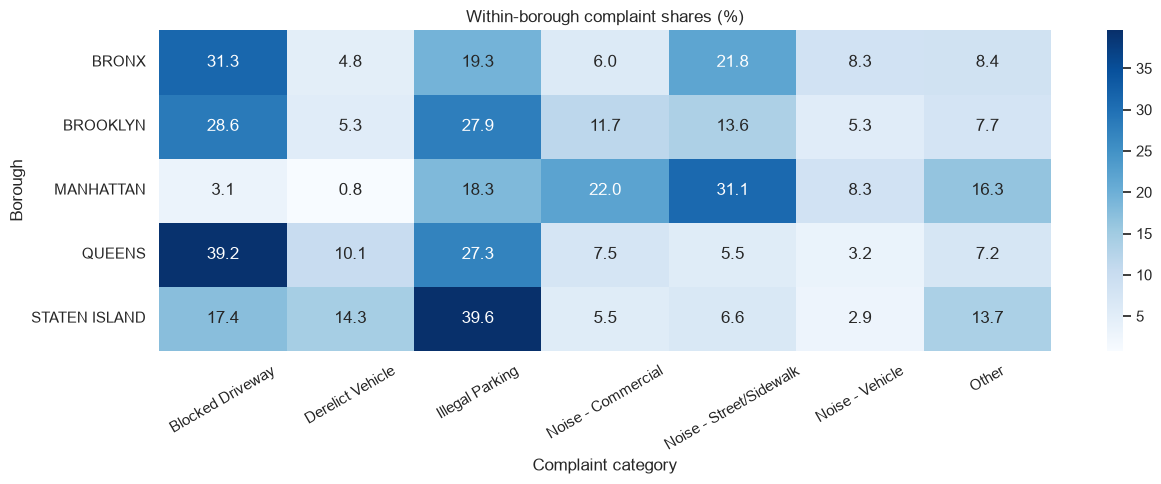

In [12]:
known_boroughs = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]
association_data = requests.loc[requests.Borough.isin(known_boroughs)].copy()
association_data["complaint_category"] = association_data["Complaint Type"].where(association_data["Complaint Type"].isin(ORIGINAL_SIX), "Other")
borough_table = pd.crosstab(association_data.Borough, association_data.complaint_category)
borough_chi = sts.chi2_contingency(borough_table, correction=False)
expected = pd.DataFrame(borough_chi.expected_freq, index=borough_table.index, columns=borough_table.columns)
if expected.to_numpy().min() < 5:
    raise ValueError("Sparse expected borough counts; revise the contingency question")
v = np.sqrt(borough_chi.statistic / (borough_table.to_numpy().sum() * min(borough_table.shape[0] - 1, borough_table.shape[1] - 1)))
association_summary = {"requests_used": len(association_data), "unknown_borough_rows_excluded": len(requests) - len(association_data),
                       "chi_square": float(borough_chi.statistic), "df": int(borough_chi.dof),
                       "pvalue": float(borough_chi.pvalue), "cramers_v": float(v),
                       "minimum_expected_count": float(expected.to_numpy().min())}
display(borough_table)
display(pd.Series(association_summary).to_frame("value"))
borough_shares = borough_table.div(borough_table.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(borough_shares, annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set(title="Within-borough complaint shares (%)", xlabel="Complaint category", ylabel="Borough")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


### Observations: complaint–borough association
The contingency analysis uses **298,124 requests** in the five known boroughs and excludes **2,574 unspecified/unknown borough records**. Its minimum expected cell count is **705.0**, so sparse expected cells are not a concern for this grouped table.

Chi-square is **62,095.5 on 24 df**, and Cramér's V is **0.228**; the p-value underflows numerically. Complaint composition varies by borough within this export. This association and heatmap describe recorded mix; they are not a comparison of borough service quality, population-adjusted complaint risk or a causal geographic effect.


## Conclusions from the verified run
Vehicle/parking and noise categories dominate this NYPD export, and most requests occur at street/sidewalk locations. Corrected durations reveal a meaningful multi-day tail: the overall mean is about 4.31 hours, while the median is about 2.71 hours. Mean alone conceals much of the distribution, and closed-only statistics cannot characterize unresolved requests.

Descriptive probabilities, city/location denominators, date exposure and complaint-specific counts are now explicit. The original grouped tables and response-time views are retained, while the >6-hour section uses the actual threshold. Pairwise comparisons are unique, use Welch intervals/effects and adjust a stated family; the daily block analysis illustrates dependence sensitivity.

The results are exploratory statistics for the current source, run with **SEED=42**. Agency scope, reporting behavior, repeated incidents, temporal/spatial dependence, differing complaint mix and closure selection limit wider inference. No predictive, clustering or forecasting model is fitted. If the source or settings change, refresh these written observations from the new outputs.


## Method references
The implementation follows the APIs and assumptions in [SciPy's Welch/trimmed t-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html), [SciPy's count-table chi-square documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.chi2_contingency.html), [SciPy's median-centered Levene documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html), and statsmodels' [Holm correction](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html) and [Wilson proportion interval](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html) documentation.
